In [7]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

In [3]:
url ='https://raw.githubusercontent.com/codebasics/py/master/ML/13_kmeans/income.csv'
df = pd.read_csv(url)
df

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000
5,Gautam,39,155000
6,David,41,160000
7,Andrea,38,162000
8,Brad,36,156000
9,Angelina,35,130000


In [4]:
# plt.figure(dpi=1000)

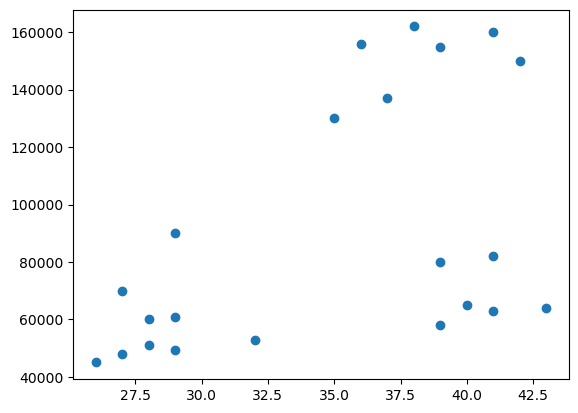

In [5]:
plt.scatter(df['Age'],df['Income($)'])

In [8]:
km = KMeans(n_clusters=3)
km

KMeans(n_clusters=3)

In [9]:
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

array([2, 2, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0])

In [10]:
df['cluster'] = y_predicted
df

,Name,Age,Income($),cluster
0,Rob,27,70000,2
1,Michael,29,90000,2
2,Mohan,29,61000,0
3,Ismail,28,60000,0
4,Kory,42,150000,1
5,Gautam,39,155000,1
6,David,41,160000,1
7,Andrea,38,162000,1
8,Brad,36,156000,1
9,Angelina,35,130000,1


In [15]:
df0 = df[df.cluster==0]
df1 = df[df.cluster==1]
df2 = df[df.cluster==2]

Text(0, 0.5, 'Income ($)')

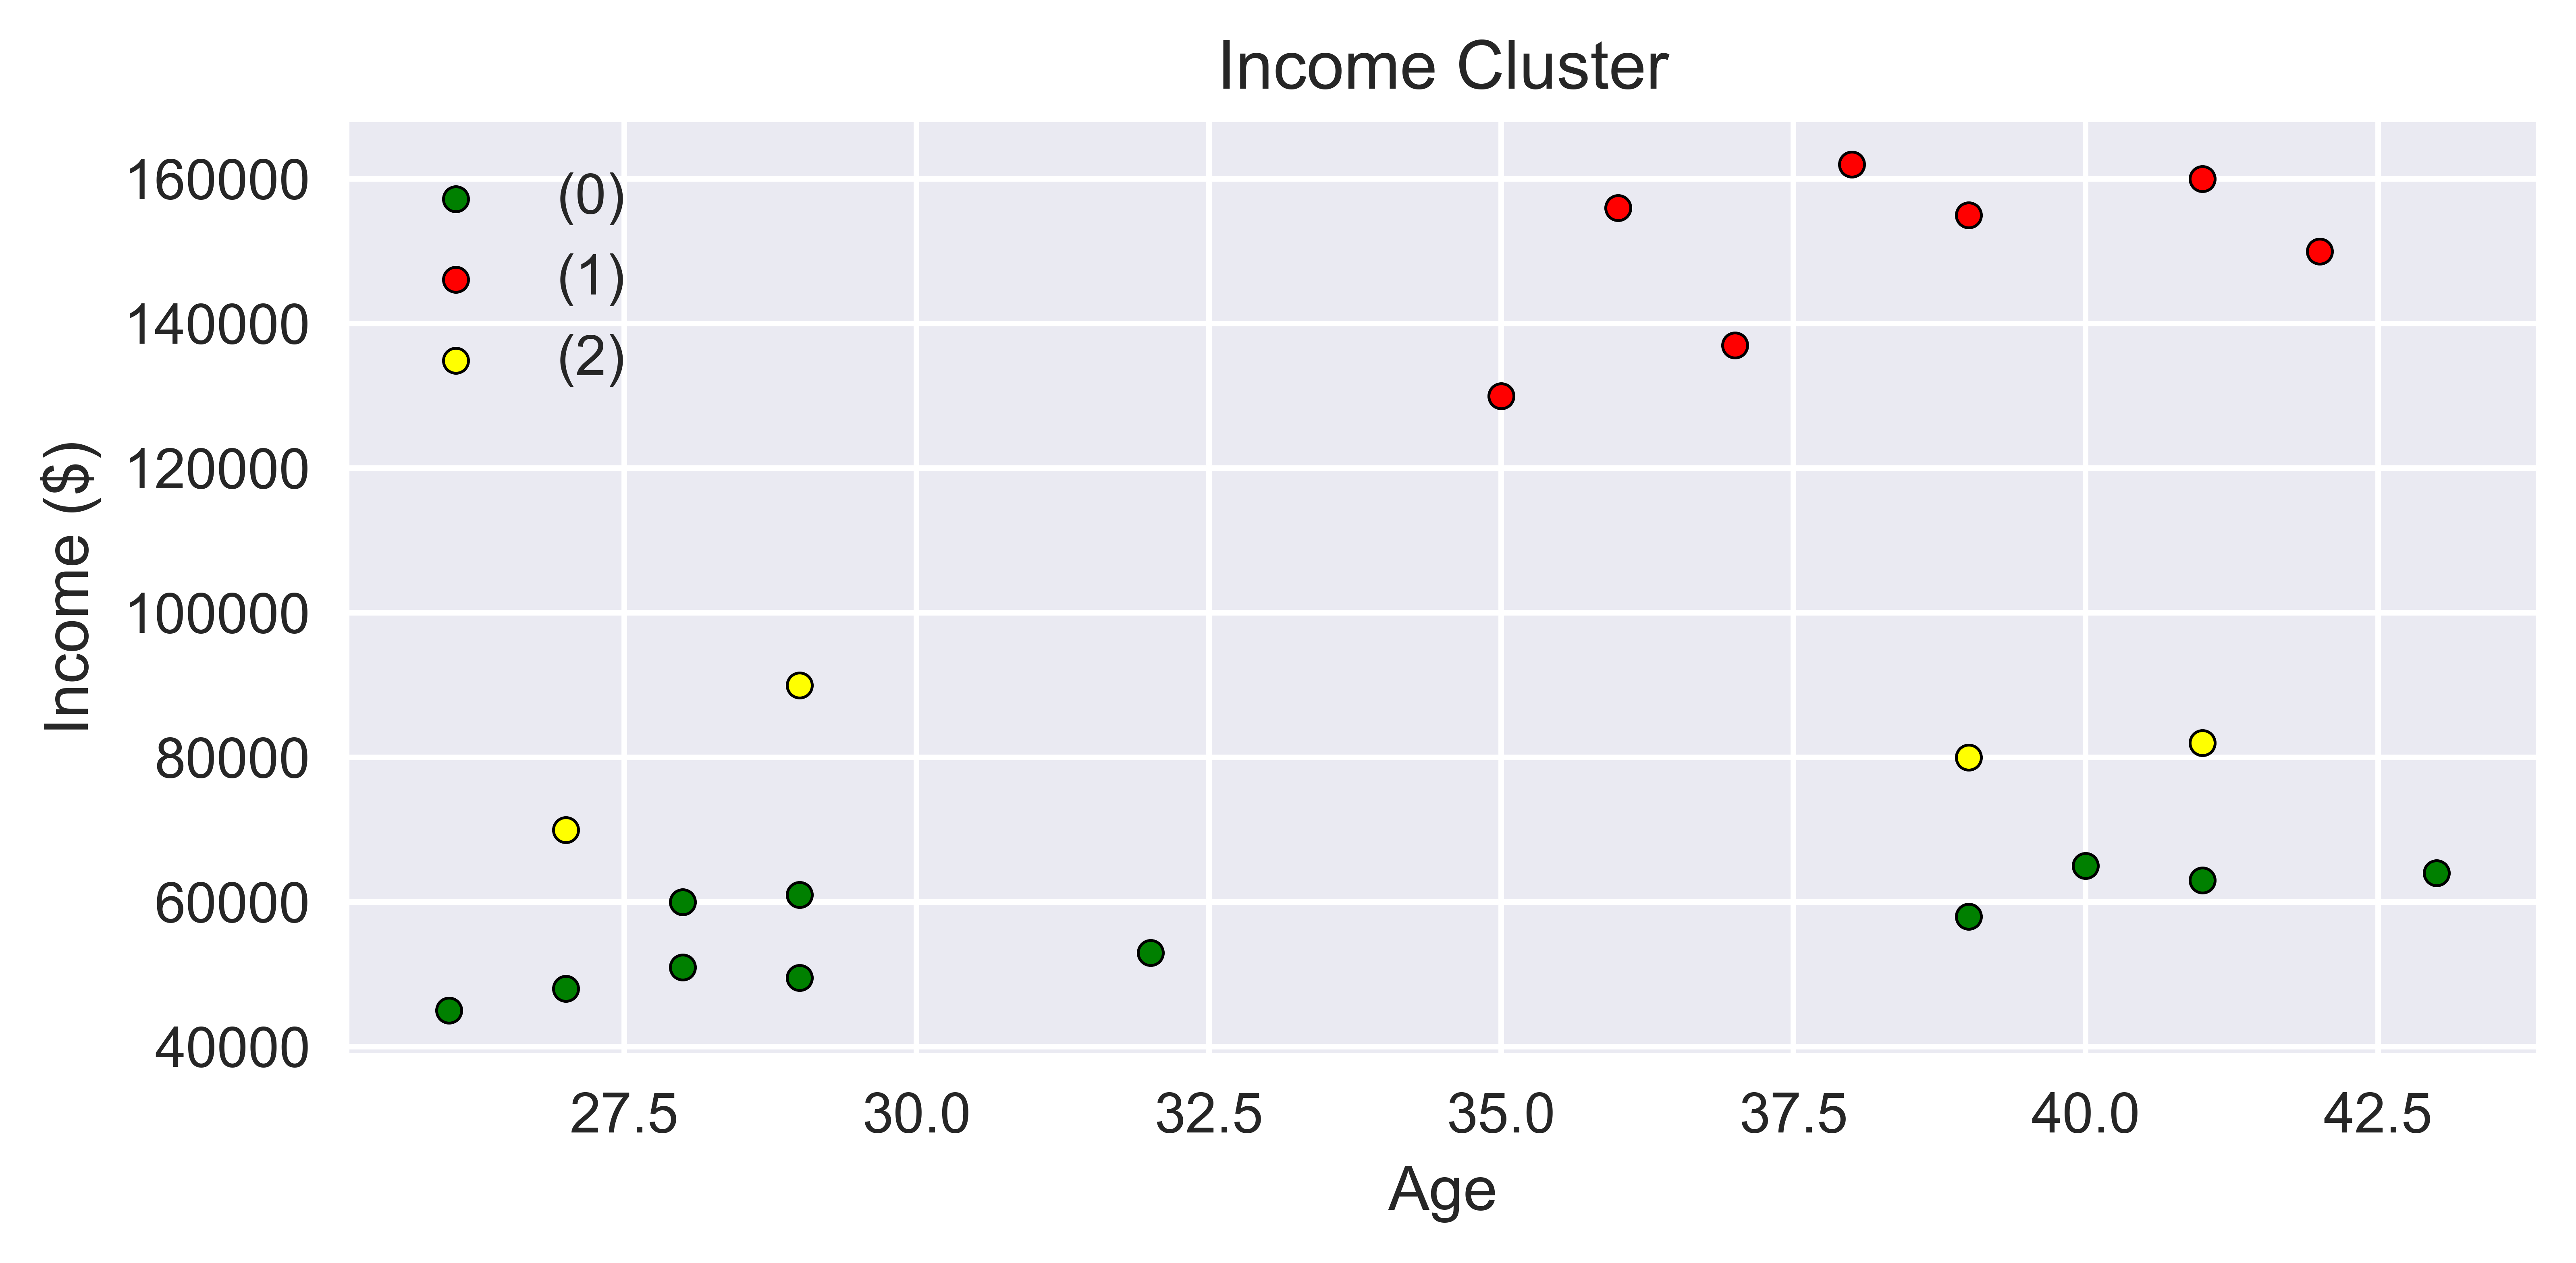

In [26]:
# plt.figure(figsizedpi=1000)
plt.figure(figsize=(7, 3),dpi=1000)
plt.style.use('seaborn')
plt.scatter(df0['Age'],df0['Income($)'],color='green',marker='o',s=20,edgecolor='black',linewidth=0.5,label='(0)')
plt.scatter(df1['Age'],df1['Income($)'],color='red',marker='o',s=20,edgecolor='black',linewidth=0.5,label='(1)')
plt.scatter(df2['Age'],df2['Income($)'],color='yellow',marker='o',s=20,edgecolor='black',linewidth=0.5,label='(2)')
plt.legend()
plt.title('Income Cluster')
plt.xlabel('Age')
plt.ylabel('Income ($)')

In [31]:
scaler = MinMaxScaler()
scaler.fit(df[['Income($)']])
df['Income($)'] = scaler.transform(df[['Income($)']])

scaler.fit(df[['Age']])
df['Age'] = scaler.transform(df[['Age']])

df

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,2
1,Michael,0.176471,0.384615,2
2,Mohan,0.176471,0.136752,0
3,Ismail,0.117647,0.128205,0
4,Kory,0.941176,0.897436,1
5,Gautam,0.764706,0.940171,1
6,David,0.882353,0.982906,1
7,Andrea,0.705882,1.000000,1
8,Brad,0.588235,0.948718,1
9,Angelina,0.529412,0.726496,1


In [32]:
km = KMeans(n_clusters=3)
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2])

In [36]:
df['cluster'] = y_predicted
df

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,0
1,Michael,0.176471,0.384615,0
2,Mohan,0.176471,0.136752,0
3,Ismail,0.117647,0.128205,0
4,Kory,0.941176,0.897436,1
5,Gautam,0.764706,0.940171,1
6,David,0.882353,0.982906,1
7,Andrea,0.705882,1.000000,1
8,Brad,0.588235,0.948718,1
9,Angelina,0.529412,0.726496,1


Text(0, 0.5, 'Income ($)')

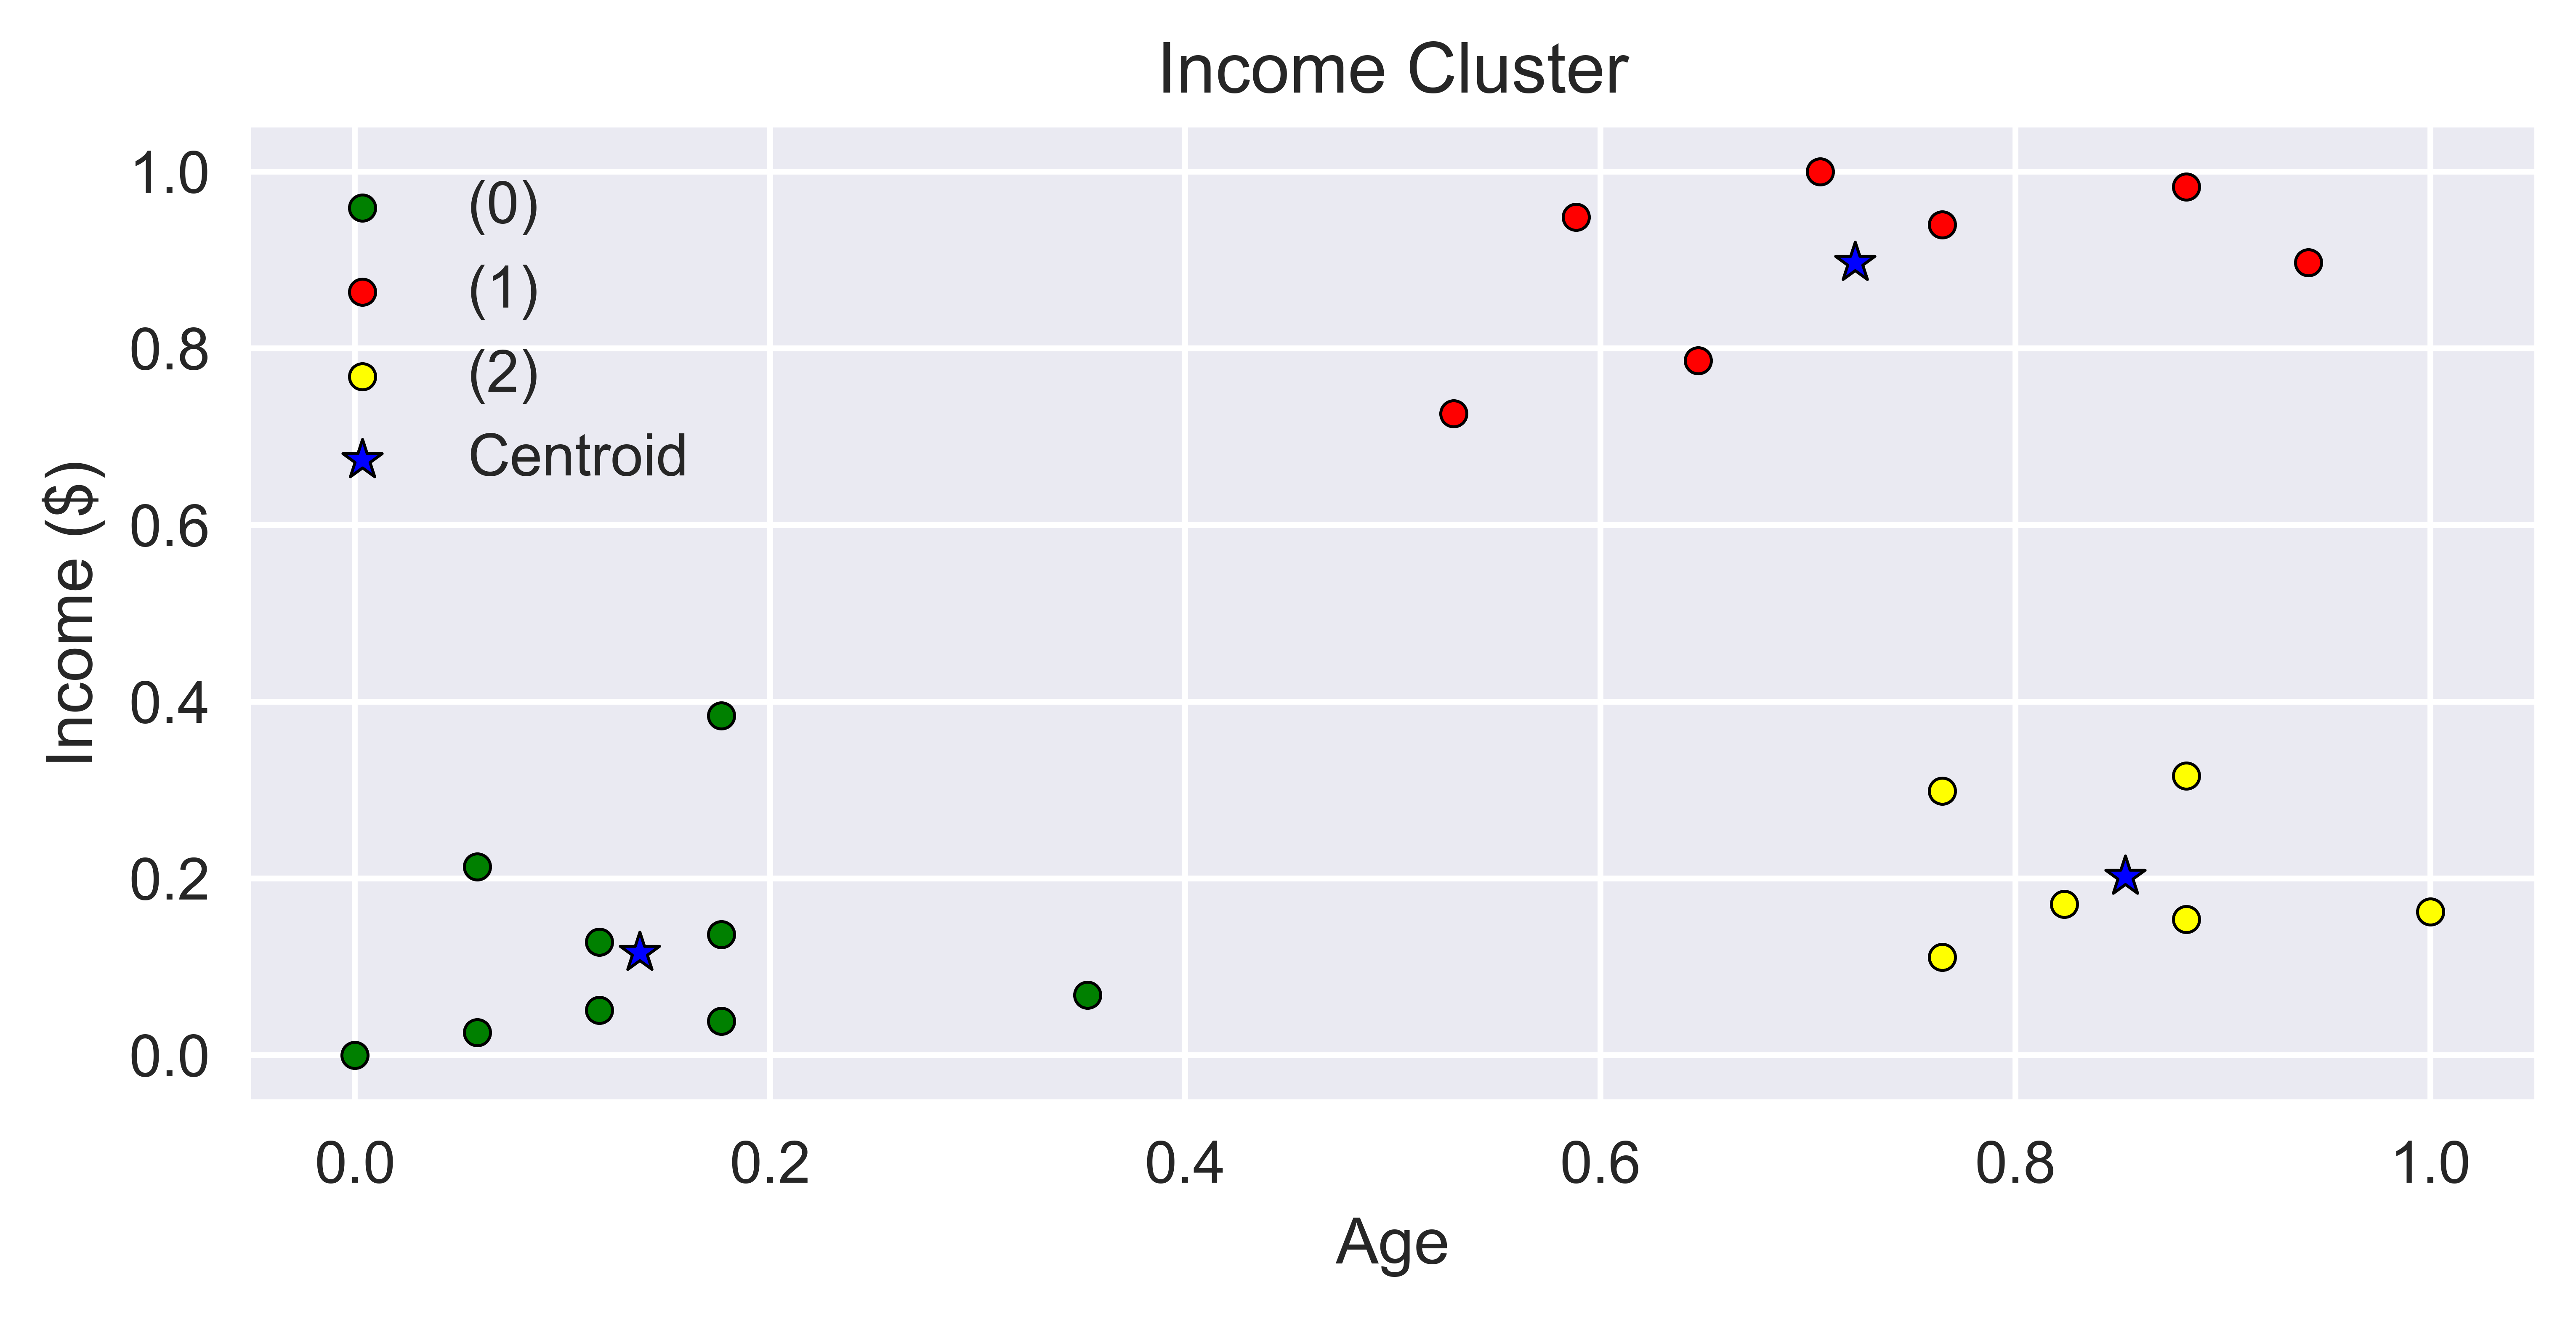

In [41]:
df0 = df[df.cluster==0]
df1 = df[df.cluster==1]
df2 = df[df.cluster==2]

plt.figure(figsize=(7, 3),dpi=1000)
plt.style.use('seaborn')
plt.scatter(df0['Age'],df0['Income($)'],color='green',marker='o',s=20,edgecolor='black',linewidth=0.5,label='(0)')
plt.scatter(df1['Age'],df1['Income($)'],color='red',marker='o',s=20,edgecolor='black',linewidth=0.5,label='(1)')
plt.scatter(df2['Age'],df2['Income($)'],color='yellow',marker='o',s=20,edgecolor='black',linewidth=0.5,label='(2)')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='blue',marker='*',s=50,edgecolor='black',linewidth=0.5,label='Centroid')

plt.legend()
plt.title('Income Cluster')
plt.xlabel('Age')
plt.ylabel('Income ($)')

In [40]:
km.cluster_centers_

array([[0.1372549 , 0.11633428],
       [0.72268908, 0.8974359 ],
       [0.85294118, 0.2022792 ]])

In [59]:
k_range = range(1,10)
sse = []
for k in k_range:
    km = KMeans(n_clusters=k)
    km.fit(df[['Age','Income($)']])
    sse.append(km.inertia_)

In [60]:
sse

[5.434011511988176,
 2.0911363886990766,
 0.47507834985530933,
 0.3491047094419564,
 0.27558255687229755,
 0.22020960864009395,
 0.16858512236029757,
 0.1327661931978319,
 0.10188787724979426]

Text(0, 0.5, 'SSE')

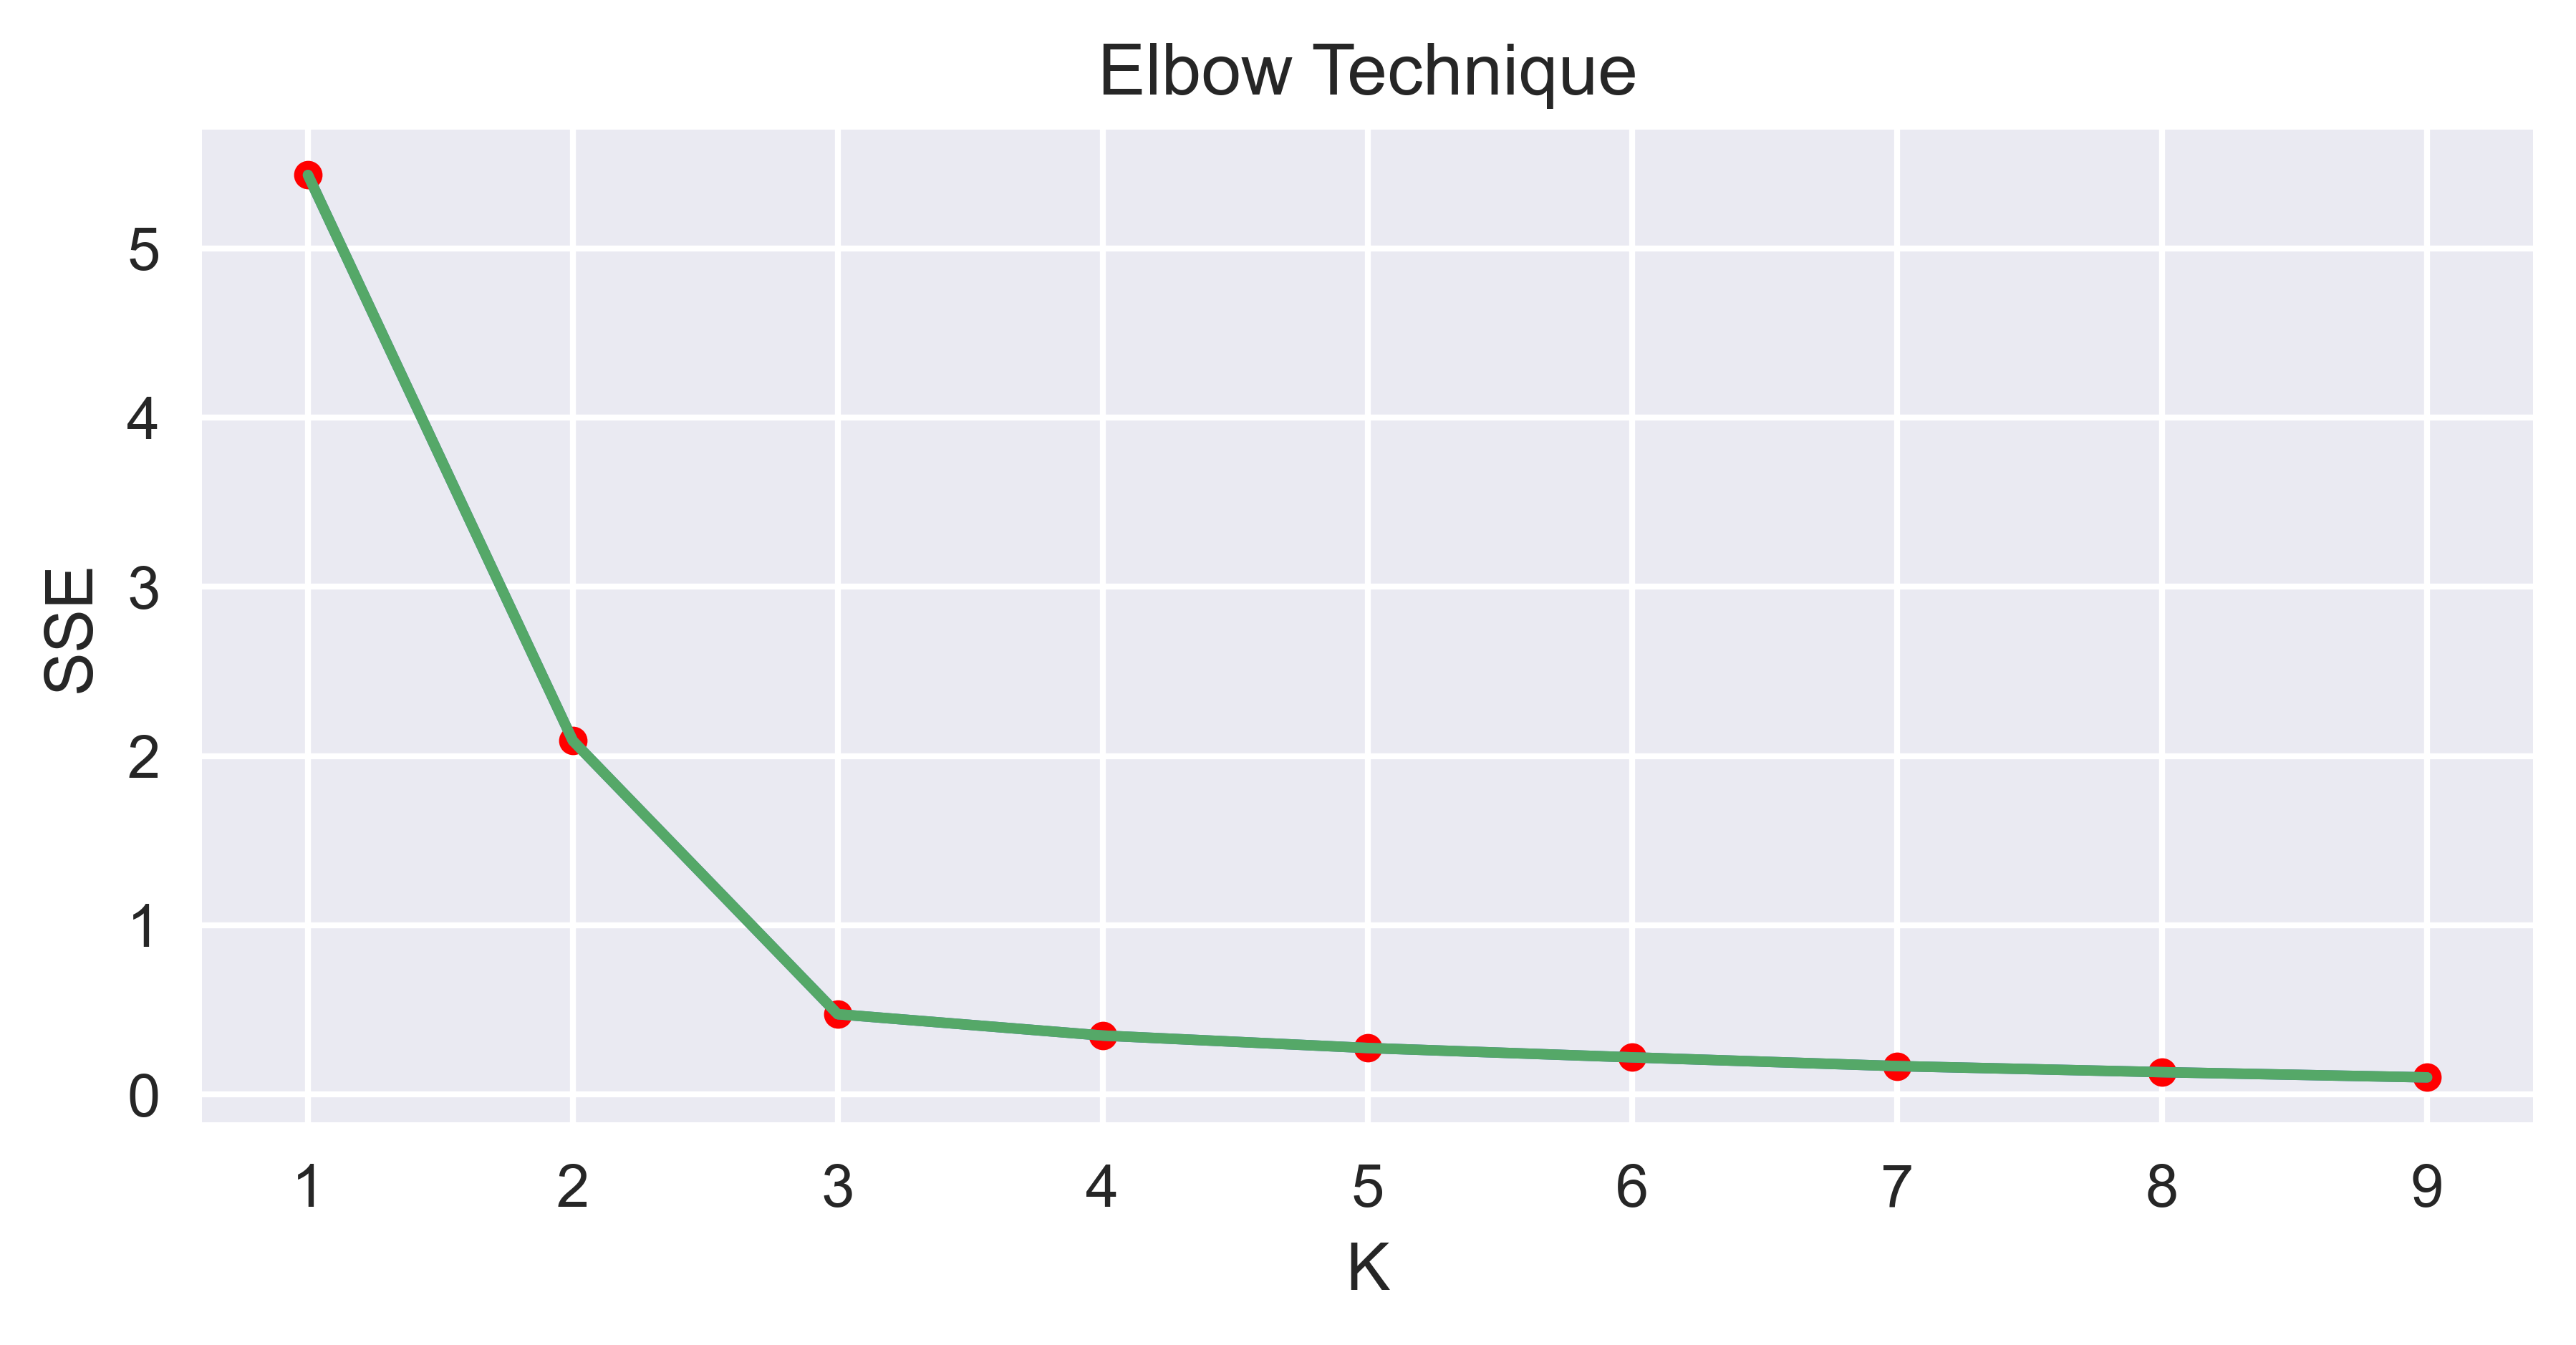

In [61]:
plt.figure(figsize=(7,3),dpi=600)
plt.plot(k_range,sse)
plt.scatter(k_range,sse,color='red',marker='o',s=20)
plt.plot(k_range,sse)
plt.title('Elbow Technique')
plt.xlabel('K')
plt.ylabel('SSE')

## Sources

Source: [Codebasics](https://github.com/codebasics/py).